# 02 · 제철 지수와 분류

`01_load_clean` 결과로 관광지 × 월마다 **제철 지수**를 계산하고, 제철 명소 · 숨은 제철 · 늘 인기로 나눈 뒤, 과거 자료로 맞혀 보며 검증한다.

- 데이터는 **제주 지역별 인기 장소**(티맵 내비 도착) 파일 하나만 쓴다.
- **제철 지수(SI)** = 그 달 비중 ÷ 12개월 평균 비중. 1.0이면 평소, 2.0이면 평소의 2배.
- 비중 = 그 관광지 도착 ÷ 그 달 제주 전체 도착. 기준 연도의 같은 달끼리 평균 낸다.

**결과물**
- `data/processed/si_place_month.csv` 관광지 × 12개월 지수와 분류
- `web/public/data/2026-MM.json` 웹이 읽는 월별 파일 12개와 `months.json` (좌표·사진은 아직 비어 있음)

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 옵션(BASE_YEARS, SI_TH, NEED_YEARS, TOP, LOW_TOURIST, 검증 연도 등)은 00_settings.ipynb에서 바꾼다
%run settings.py
print(f"기준 연도 {BASE_YEARS} · 제철 SI ≥ {SI_TH}, {min(NEED_YEARS, len(BASE_YEARS))}년 이상 · "
      f"인기 상위 {TOP:.0%} · 도민 위주 하위 {LOW_TOURIST:.0%} · 검증 {VALID_TRAIN_YEARS} → {VALID_TEST_YEAR}")

plt.rcParams["font.family"] = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

PROC = Path("../data/processed")
WEB = Path("../web/public/data")

기준 연도 [2024, 2025] · 제철 SI ≥ 1.5, 2년 이상 · 인기 상위 20% · 도민 위주 하위 30% · 검증 [2023, 2024] → 2025


## 1. 불러오기

In [2]:
pm = pd.read_csv(PROC / "place_month.csv", encoding="utf-8-sig")
month_total = pd.read_csv(PROC / "month_total.csv", encoding="utf-8-sig")
places = pd.read_csv(PROC / "places.csv", encoding="utf-8-sig").set_index("place_id")

pm = pm.merge(month_total, on="ym")
pm["share"] = pm["arrive"] / pm["total"]   # 그 달 제주 전체 도착 대비 비중
pm["year"] = pm["ym"] // 100
pm["m"] = pm["ym"] % 100
print(f"{pm.place_id.nunique():,}곳 × {pm.ym.nunique()}개월")
pm.head()

365곳 × 60개월

,place_id,ym,arrive,tourist,local,name,emd,cat,total,share,year,m
0,1100고지 코스|39020620,202101,609,387,215,1100고지 코스,예래동,드라이브코스,830733,0.000733,2021,1
1,1100고지 코스|39020620,202102,581,402,175,1100고지 코스,예래동,드라이브코스,1213236,0.000479,2021,2
2,1100고지 코스|39020620,202103,436,285,147,1100고지 코스,예래동,드라이브코스,1509382,0.000289,2021,3
3,1100고지 코스|39020620,202104,451,292,159,1100고지 코스,예래동,드라이브코스,1751024,0.000258,2021,4
4,1100고지 코스|39020620,202105,456,300,152,1100고지 코스,예래동,드라이브코스,1859947,0.000245,2021,5


## 2. 제철 지수와 분류 계산

한 번 만들어 두고 기준 연도만 바꿔서 두 번 쓴다. 서비스용(`BASE_YEARS`)과 검증용(`VALID_TRAIN_YEARS`)이다.

| 분류 | 조건 (기본값) |
|---|---|
| 제철 명소 | SI ≥ `SI_TH`(1.5), 기준 연도 중 `NEED_YEARS`(2)년 이상 그 해에도 1.5 이상, 이번 달 인기(상위 `TOP` 20%) |
| 숨은 제철 | 위와 같은 제철인데 인기 밖이거나, 관광객 비중 하위 `LOW_TOURIST`(30%)(도민이 주로 찾음) |
| 늘 인기 | SI < 1.5 인데 이번 달 인기 |
| 제외 | 나머지. SI가 1.5 이상이어도 한 해만 튄 곳은 여기로 간다 |

In [3]:
def seasonality(pm, years):
    b = pm[pm["year"].isin(years)].copy()

    # 해마다 따로 낸 SI: 그 해 12개월 평균 비중 대비 (일관성 확인용)
    b["si_year"] = b["share"] / b.groupby(["place_id", "year"])["share"].transform("mean")

    g = b.groupby(["place_id", "m"])
    t = g.agg(share=("share", "mean"),            # 기준 연도 같은 달 비중의 평균
              arrive=("arrive", "mean"),          # 기준 연도 같은 달 실제 도착 평균 (한산한 달·늘 인기 정렬용)
              tourist=("tourist", "sum"), local=("local", "sum"))
    t["hot_years"] = g["si_year"].apply(lambda s: int((s >= SI_TH).sum()))

    # 제철 지수 = 그 달 비중 ÷ 12개월 평균 비중
    t["si"] = t["share"] / t.groupby(level="place_id")["share"].transform("mean")

    # 이번 달 인기: 같은 달 관광지끼리 비중 순위 (0~1, 1이 가장 높음)
    t["rank_pct"] = t.groupby(level="m")["share"].rank(pct=True)
    t["top"] = t["rank_pct"] > 1 - TOP

    # 관광객 비중과 '도민이 주로 찾는 곳'
    t["tourist_share"] = t["tourist"] / (t["tourist"] + t["local"]).replace(0, np.nan)
    t["low_tourist"] = t.groupby(level="m")["tourist_share"].rank(pct=True) <= LOW_TOURIST

    seasonal = (t["si"] >= SI_TH) & (t["hot_years"] >= min(NEED_YEARS, len(years)))
    t["class"] = np.select(
        [seasonal & (~t["top"] | t["low_tourist"]), seasonal, t["top"] & (t["si"] < SI_TH)],
        ["hidden", "peak", "steady"], default="none")
    return t.reset_index()


si = seasonality(pm, BASE_YEARS)
si = si.merge(places[["name", "emd", "cat"]], left_on="place_id", right_index=True)
print("월별 분류 개수")
si.pivot_table(index="m", columns="class", values="place_id", aggfunc="count", fill_value=0)

월별 분류 개수


class,hidden,none,peak,steady
m,,,,
1,13,279,4,69
2,11,282,8,64
3,11,284,8,62
4,17,278,8,62
5,5,290,1,69
6,8,286,4,67
7,19,277,8,61
8,24,276,13,52
9,6,288,1,70


## 3. 한 달 결과 보기 (`VIEW_MONTH`, 기본 10월)

In [4]:
MONTH = VIEW_MONTH
view = si[si["m"] == MONTH].sort_values("si", ascending=False)
cols = ["name", "emd", "cat", "si", "arrive", "hot_years", "rank_pct", "tourist_share", "class"]
for c, label in [("peak", "제철 명소"), ("hidden", "숨은 제철"), ("steady", "늘 인기")]:
    sub = view[view["class"] == c]
    if c == "steady":   # 늘 인기는 방문 많은 순
        sub = sub.sort_values("arrive", ascending=False)
    print(f"\n{MONTH}월 {label} {len(sub)}곳")
    display(sub[cols].head(15).round(2))


10월 제철 명소 5곳


,name,emd,cat,si,arrive,hot_years,rank_pct,tourist_share,class
2649,와흘메밀마을/체험힐링센터,조천읍,체험학습,3.55,752.0,2,0.84,0.54,peak
1401,산굼부리,조천읍,관광단지,2.87,2905.5,2,0.97,0.60,peak
1581,새별오름,애월읍,오름,2.27,4893.5,2,0.99,0.54,peak
3993,파더스가든,안덕면,관광명소기타,2.21,831.5,2,0.84,0.70,peak
669,닭머르해안길,조천읍,여행/레저기타,1.68,742.0,2,0.83,0.61,peak



10월 숨은 제철 9곳


,name,emd,cat,si,arrive,hot_years,rank_pct,tourist_share,class
2481,어음리억새군락지,애월읍,관광명소기타,2.99,326.5,2,0.63,0.62,hidden
2589,오라동메밀밭,연동,관광명소기타,2.48,342.0,2,0.64,0.56,hidden
2793,우도정원,우도면,동식물원,2.25,128.0,2,0.33,0.63,hidden
933,따라비오름,표선면,오름,2.22,613.5,2,0.79,0.38,hidden
705,대록산,표선면,명산,2.19,120.0,2,0.31,0.21,hidden
429,길갈팜랜드,조천읍,체험학습,2.11,485.5,2,0.75,0.53,hidden
3789,차귀도선셋유람선,한경면,여행/레저기타,1.65,129.5,2,0.33,0.53,hidden
2637,옷귀마테마타운,남원읍,관광명소기타,1.65,151.0,2,0.39,0.24,hidden
3417,제주신산공원,일도2동,공원,1.63,353.0,2,0.65,0.17,hidden



10월 늘 인기 65곳


,name,emd,cat,si,arrive,hot_years,rank_pct,tourist_share,class
1845,성산일출봉,성산읍,명산,1.08,6897.5,0,1.00,0.64,steady
4233,함덕해수욕장,조천읍,해수욕장,0.99,6524.0,0,1.00,0.56,steady
4281,협재해수욕장,한림읍,해수욕장,0.98,5203.0,0,0.99,0.67,steady
2601,오설록티뮤지엄,안덕면,박물관/기념관,0.99,4704.5,0,0.99,0.64,steady
1821,섭지코지,성산읍,관광명소기타,1.16,3940.5,0,0.99,0.66,steady
2349,아쿠아플라넷/제주,성산읍,수족관,0.99,3628.5,0,0.98,0.66,steady
1329,비자림,구좌읍,자연휴양림,1.17,3354.5,0,0.98,0.61,steady
3729,주상절리대,중문동,관광명소기타,1.17,3151.0,0,0.98,0.65,steady
2733,용머리해안,안덕면,관광명소기타,1.08,3147.5,0,0.98,0.66,steady
3009,이호테우해변,이호동,해수욕장,0.93,2996.0,0,0.97,0.63,steady


## 4. 관광지 하나 자세히 보기

막대가 점선(평소 = 1) 위로 크게 솟은 달이 제철이다.

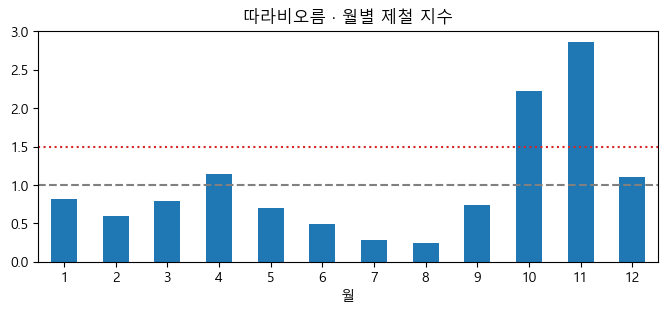

In [5]:
name = EXAMPLE_SEASONAL
one = si[si["name"] == name].sort_values("m")
ax = one.plot.bar(x="m", y="si", figsize=(8, 3), legend=False, title=f"{name} · 월별 제철 지수", rot=0)
ax.axhline(1, ls="--", c="gray")
ax.axhline(SI_TH, ls=":", c="tab:red")
ax.set_xlabel("월");

## 5. 검증 (백테스트)

`VALID_TRAIN_YEARS`(기본 2023~2024)만으로 지수를 계산한 뒤, `VALID_TEST_YEAR`(기본 2025)에 실제로 그렇게 나왔는지 맞혀 본다.

- **제철 적중률**: 제철이라고 예측한 (관광지, 월) 중 검증 연도에도 SI가 1.5 이상인 비율. 바로 전 한 해만 보고 예측했을 때와 비교한다.
- **절정 월 오차**: 예측한 가장 높은 달과 검증 연도 실제 가장 높은 달이 ±1개월 안인 비율.

In [6]:
train = seasonality(pm, VALID_TRAIN_YEARS)
naive = seasonality(pm, VALID_TRAIN_YEARS[-1:])   # 비교용: 바로 전 한 해만 보고 예측

test = pm[pm["year"] == VALID_TEST_YEAR].copy()
test["si_test"] = test["share"] / test.groupby("place_id")["share"].transform("mean")
test = test[["place_id", "m", "si_test"]]

def hit_rate(pred):
    p = pred[pred["class"].isin(["peak", "hidden"])].merge(test, on=["place_id", "m"])
    return len(p), (p["si_test"] >= SI_TH).mean(), (p["si_test"] >= 1.0).mean()

train_label = f"{VALID_TRAIN_YEARS[0]}~{VALID_TRAIN_YEARS[-1]} · {min(NEED_YEARS, len(VALID_TRAIN_YEARS))}년 이상 기준 이상"
for label, pred in [(train_label, train), (f"{VALID_TRAIN_YEARS[-1]}년 한 해만", naive)]:
    n, strict, loose = hit_rate(pred)
    print(f"{label}: 제철 예측 {n}건 → {VALID_TEST_YEAR}년에도 1.5 이상 {strict:.0%}, 평소(1.0) 이상 {loose:.0%}")

# 절정 월 오차: 제철이 뚜렷한 곳(예측 최대 SI ≥ 1.5)만
train_ok = train.dropna(subset=["si"])
peak_pred = train_ok.loc[train_ok.groupby("place_id")["si"].idxmax(), ["place_id", "m", "si"]]
peak_pred = peak_pred[peak_pred["si"] >= SI_TH]
test_ok = test.dropna(subset=["si_test"])   # 검증 연도에 도착이 한 건도 없던 곳은 뺀다
peak_true = test_ok.loc[test_ok.groupby("place_id")["si_test"].idxmax(), ["place_id", "m"]]
pk = peak_pred.merge(peak_true, on="place_id", suffixes=("_pred", "_test"))
gap = (pk["m_pred"] - pk["m_test"]).abs()
gap = np.minimum(gap, 12 - gap)   # 12월과 1월은 1개월 차이
print(f"절정 월: {len(pk)}곳 중 ±1개월 안 {(gap <= 1).mean():.0%}, 정확히 같은 달 {(gap == 0).mean():.0%}")

2023~2024 · 2년 이상 기준 이상: 제철 예측 194건 → 2025년에도 1.5 이상 80%, 평소(1.0) 이상 95%
2024년 한 해만: 제철 예측 407건 → 2025년에도 1.5 이상 52%, 평소(1.0) 이상 81%
절정 월: 170곳 중 ±1개월 안 71%, 정확히 같은 달 45%


## 6. 알려진 제철 관광지 재현율

실행 가이드 8번 표를 데이터 속 이름으로 옮긴 것이다(`KNOWN`, 00_settings에 있음). 예상 월(±1개월)에 제철 명소나 숨은 제철로 분류되면 맞힌 것으로 본다.

데이터에 없는 곳(전농로, 한라산 영실)은 비슷한 계절 명소(성산유채꽃밭, 동백포레스트)로 바꿨다. 이 목록은 결과를 보고 고치지 않는다.

In [7]:
def near(months):   # 예상 월 ±1개월
    return {((m + d - 1) % 12) + 1 for m in months for d in (-1, 0, 1)}

rows = []
for name, months in KNOWN.items():
    s = si[si["name"] == name]
    hot = s[s["class"].isin(["peak", "hidden"])]
    found = sorted(hot["m"].tolist())
    rows.append({"관광지": name, "예상 월": months, "지수가 찾은 제철 월": found,
                 "맞힘": bool(set(found) & near(months)) if len(s) else None})
known = pd.DataFrame(rows)
print(f"재현율: {known['맞힘'].sum()} / {known['맞힘'].notna().sum()}곳 (분석 대상에 없는 곳 {known['맞힘'].isna().sum()}곳 제외)")
known

재현율: 18 / 20곳 (분석 대상에 없는 곳 0곳 제외)


,관광지,예상 월,지수가 찾은 제철 월,맞힘
0,녹산로유채꽃도로,"[3, 4]","[3, 4]",True
1,산방산유채꽃밭,"[3, 4]","[2, 3, 4]",True
2,성산유채꽃밭,"[3, 4]","[1, 2, 3]",True
3,오라동메밀밭,[5],"[5, 6, 10]",True
4,답다니수국밭,[6],[6],True
5,종달리수국길,[6],[6],True
6,혼인지,[6],[6],True
7,원앙폭포,"[7, 8]","[7, 8]",True
8,태웃개,"[7, 8]","[7, 8, 9]",True
9,논짓물,"[7, 8]",[7],True


## 7. 저장

In [8]:
si.to_csv(PROC / "si_place_month.csv", index=False, encoding="utf-8-sig")
print("저장:", PROC / "si_place_month.csv", f"{len(si):,}행")

저장: ..\data\processed\si_place_month.csv 4,380행


## 8. 웹용 월별 JSON

실행 가이드 2번 형식이다. 좌표(lat, lng)와 사진은 아직 비어 있다. 카카오 로컬로 좌표를 붙이는 단계에서 채운다.
`why`는 지수로 만든 자동 문구이고, 10·11월 상위 관광지는 나중에 직접 쓴 문구로 바꾼다.

In [9]:
WEB.mkdir(parents=True, exist_ok=True)

ids = {pid: f"p{i:04d}" for i, pid in enumerate(sorted(si["place_id"].unique()), 1)}
wide = si.pivot(index="place_id", columns="m", values="si").reindex(columns=range(1, 13))
monthly_si = {pid: [round(v, 2) for v in row] for pid, row in wide.iterrows()}
max_si = wide.max(axis=1).round(2).to_dict()   # 12개월 중 최대 SI (계절 특화도)
# 가장 한산한 달 = 실제 도착 수가 가장 적은 달 (비중이 아니라)
quiet = si.pivot(index="place_id", columns="m", values="arrive").idxmin(axis=1).to_dict()

def why(r):
    if r["class"] == "peak":
        return f"{r.m}월 방문이 평소의 {r.si:.1f}배예요."
    if r["class"] == "hidden":
        if r["low_tourist"]:
            return f"{r.m}월 방문이 평소의 {r.si:.1f}배인데, 찾는 사람 대부분이 도민이에요."
        return f"아직 덜 알려졌지만 {r.m}월 방문이 평소의 {r.si:.1f}배예요."
    return f"1년 내내 붐비는 곳이에요. 가장 한산한 달은 {quiet[r.place_id]}월이에요."

for m in range(1, 13):
    rows = si[(si["m"] == m) & (si["class"] != "none")].copy()
    # 제철 명소·숨은 제철은 SI 높은 순, 늘 인기는 방문 많은 순
    rows["order"] = rows["class"].map({"peak": 0, "hidden": 1, "steady": 2})
    rows["key"] = np.where(rows["class"] == "steady", rows["arrive"], rows["si"])
    rows = rows.sort_values(["order", "key"], ascending=[True, False])
    data = {
        "month": f"{SERVICE_YEAR}-{m:02d}",
        "theme": {"title": f"{m}월의 제주", "tagline": "", "tint": THEME_TINT},
        "places": [{
            "id": ids[r.place_id], "name": r["name"], "type": r["class"],
            "lat": None, "lng": None, "area": r["emd"], "tags": [r["cat"]],
            "why": why(r),
            "evidence": {"visitSI": round(r.si, 2),
                         "localShare": None if pd.isna(r.tourist_share) else round(1 - r.tourist_share, 2)},
            "localBadge": bool(r.low_tourist),
            "monthlySI": monthly_si[r.place_id],
            "maxSI": max_si[r.place_id],
            "quietMonth": int(quiet[r.place_id]) if r["class"] == "steady" else None,
            "nearby": [], "photo": None,
        } for _, r in rows.iterrows()],
    }
    (WEB / f"{SERVICE_YEAR}-{m:02d}.json").write_text(json.dumps(data, ensure_ascii=False, indent=1), encoding="utf-8")

(WEB / "months.json").write_text(json.dumps(OPEN_MONTHS), encoding="utf-8")
print("저장:", sorted(p.name for p in WEB.glob("*.json")))

저장: ['2026-01.json', '2026-02.json', '2026-03.json', '2026-04.json', '2026-05.json', '2026-06.json', '2026-07.json', '2026-08.json', '2026-09.json', '2026-10.json', '2026-11.json', '2026-12.json', 'months.json']
